In [53]:
# REQUIRES, IMPORTS, ETC.
# ========
# System
# ----------------
import sys, time

# Third-party libraries
# ----------------------
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# MODULES
# ========
# System modules
# --------------
from pathlib import Path
from typing import Dict
# from datetime import datetime

# Custom modules
# Defines
# -------
from src.config.globals import *

# Helpers functions
# -----------------
import src.helpers.validations as val
import src.helpers.console as csl
import src.helpers.charts as cht

In [54]:
# CHECK CHANGES ONF IMPORT FILES
# ==============================
import importlib
importlib.reload(csl)
importlib.reload(cht)
importlib.reload(val)

print(csl.__file__)
print([name for name in dir(csl)])
print("+ ")

print(cht.__file__)
print([name for name in dir(cht)])
print("+ ")

print(val.__file__)
print([name for name in dir(val)])

/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/helpers/console.py
['LineBreak', 'SectionBegin', 'SectionBreak', 'SectionEnd', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'nbsp']
+ 
/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/helpers/charts.py
['AnomaliesSummaryCht', 'BarCht', 'Dict', 'DifferenceCht', 'DuplicatedValuesCht', 'HistogramCht', 'LineCht', 'Literal', 'PlotSalesAnalytics', 'QualitySummaryCht', 'RelationalScatterCht', 'ResidualsScatterCht', 'ScatterCht', 'SequentialScatterCht', 'StripCht', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'pd', 'plt', 'sns', 'sys', 'val']
+ 
/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/helpers/validations.py
['Dict', 'ValidateParams', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', 'p

In [55]:
# GLOBAL VARIABLES, PATHS
# =====
# CURRENT FILE PATH
NOTEBOOK_DIR = Path.cwd()
DATA_DIR = (NOTEBOOK_DIR.parent / "data").resolve()

# Global variables definition for this notebook
# ---------------------------------------------
# dataset:str = "../data/ventas_con_problemas.csv"
dataset: str = DATA_DIR / "ventas_con_problemas.csv"

# Pandas dataframe to hold the dataset
df: pd.DataFrame
# Algorithm result
res: Dict[str, any]

In [56]:
# LOAD SOURCE DATASET (from CSV file)
# ===================================
csl.SectionBegin(f"DATASET PATH: \n{dataset}", 0)
csl.SectionBreak(0, 0)

try:
  df = pd.read_csv(dataset)
  print(f"File loaded successfully. Total of original rows: {len(df)}")
  print(f"First 5 rows of the dataset:")
  print(df.head())
  
except FileNotFoundError:
  print(f"Error: Please, check path. \n'{dataset}'")
  print(f"Error: File not found.")

csl.SectionEnd(0)


+ =========================================================
+ DATASET PATH: 
/home/dcueli/projects/courses/regulated/ai-and-big-data/p1/bigdata_sys/src/activities/RA1/lesson_02/data/ventas_con_problemas.csv
+ ---------------------------------------------------------
File loaded successfully. Total of original rows: 320
First 5 rows of the dataset:
  fecha             producto  cantidad  precio_unitario   total
0   NaN  Monitor 24 pulgadas       1.0           114.18  114.18
1   NaN      Cargador rapido       6.0            37.74  226.44
2   NaN  Monitor 24 pulgadas       5.0           193.91  969.55
3   NaN     Altavoz portatil       8.0           111.84  894.72
4   NaN      Cargador rapido       2.0            15.47   30.94
+ =========================================================


+ =========================================================
+ CHECK OF NULL VALUES
+ ---------------------------------------------------------
Null values per column:
fecha              5
producto           5
cantidad           5
precio_unitario    5
total              5
dtype: int64
+ ---------------------------------------------------------
Total rows with at least one null value: 
25
+ ---------------------------------------------------------


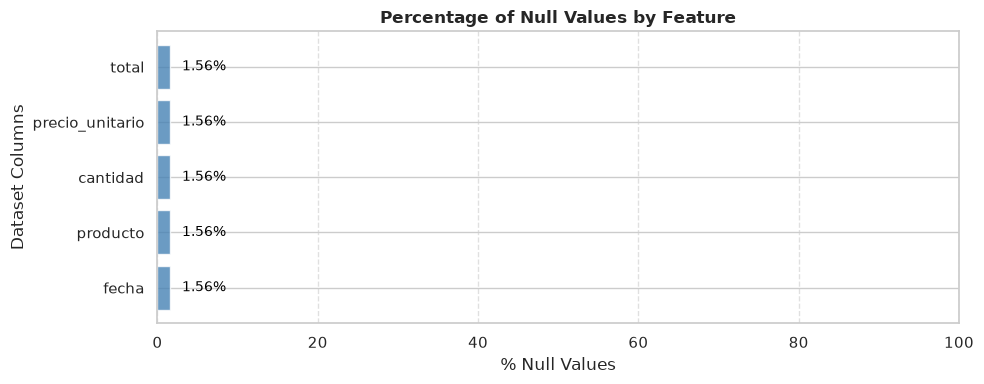

+ ---------------------------------------------------------
+ Time to load: 0.2299 seconds
+ =========================================================


In [57]:
# DATA ANALYSIS, 1. CHECK OF NULL VALUES
# ======================================
tInit: float = time.time()

# CheckNullValues
# ---------------
# Totalize and print the number of null values per column in the dataset, 
# as well as the total number of rows with at least one null value.
# 
# @param pDf: pd.DataFrame The pandas dataframe to check for null values.
# @return None
def CheckNullValues(pDf: pd.DataFrame) -> list[dict]:
  # Total null values per column in the dataset
  nullValuesPerColumn: int = pDf.isnull().sum()
  print("Null values per column:")
  print(nullValuesPerColumn)
  csl.SectionBreak(0,0)

  # Total rows with at least one null value
  rowsWithNulls: pd.DataFrame = pDf[pDf.isnull().any(axis=1)]
  print(f"Total rows with at least one null value: \n{len(rowsWithNulls)}")
  csl.SectionBreak(0,0)

  # Horizontal Bar Plot configuration
  res = cht.PlotSalesAnalytics(
    list(pDf.columns), {
    'figsize': (10, 5),
    'fontsize': 12,
    'fontweight': 'bold',
    'color': 'steelblue',
    'alpha': 0.8,
    'title': 'Percentage of Null Values by Feature',
    'xlabel': '% Null Values',
    'ylabel': 'Dataset Columns',
    'show_values': True,
    'text_cfg': {
        'offset': 1.5,
        'va': 'center',
        'ha': 'left',
        'fontsize': 10,
        'color': 'black'
      }
    }, 
    'bar',
    pDf, 
  )
  
  return res

# Execute script
csl.SectionBegin("CHECK OF NULL VALUES", 0)
csl.SectionBreak(0,0)

res = CheckNullValues(df)
if not res['bOk']: 
  print(f"Error({res['err']['code']}): In {res['err']['whre']}:")
  print(res['err']['mssg'])

csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ CHECK OF DUPLICATED VALUES
+ Summary of fully duplicate rows found
+ ---------------------------------------------------------
Just duplicated rows: 12
Source duplicated rows : 5
+ ---------------------------------------------------------
Snapshot duplicated rows: 17
 
          fecha             producto  cantidad  precio_unitario   total
117  2026-09-24         Funda tablet       2.0            11.14   22.28
315  2026-09-24         Funda tablet       2.0            11.14   22.28
116  2026-10-08     Teclado mecanico       2.0           103.16  206.32
282  2026-10-08     Teclado mecanico       2.0           103.16  206.32
301  2026-10-08     Teclado mecanico       2.0           103.16  206.32
119  2026-10-10        Disco SSD 1TB       2.0           103.23  206.46
175  2026-10-10        Disco SSD 1TB       2.0           103.23  206.46
239  2026-10-10        Disco SSD 1TB       2.0           103.23  206.46
118  2026-10-12  Mon

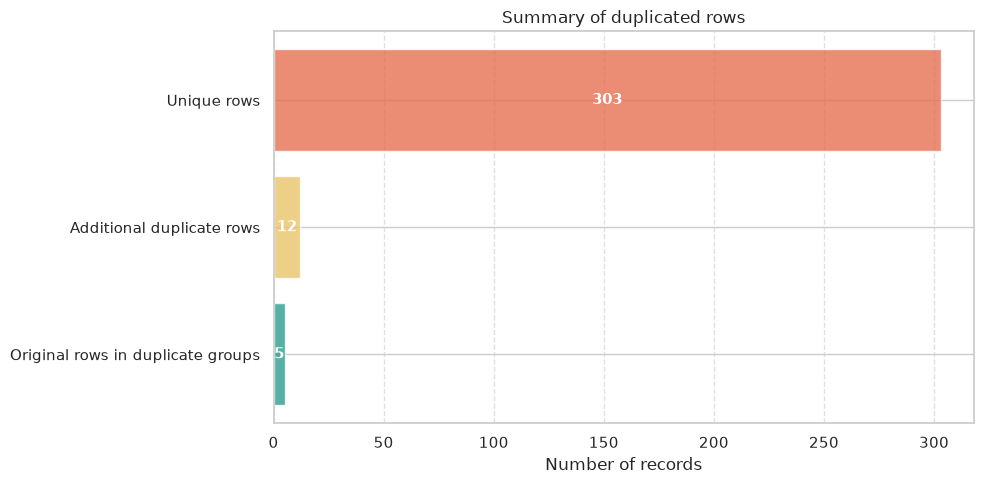

+ ---------------------------------------------------------
+ Time to load: 0.2149 seconds
+ =========================================================


In [58]:
# DATA ANALYSIS, 3. CHECK OF DUPLICATED VALUES
# ============================================
tInit: float = time.time()

# CheckDuplicatedValues
# ---------------------
# Count exactly how many rows are duplicated, taking all columns in account
# 
# @param pd.DataFrame pDf The pandas dataframe to check
# @return dict
def CheckDuplicatedValues(pDf: pd.DataFrame) -> pd.DataFrame:
  cols:list[str] = ['fecha', 'producto', 'cantidad', 'precio_unitario', 'total']
  totRows: int = len(pDf)
  duplRowsOnly: pd.DataFrame = pDf[pDf.duplicated(subset=cols)]
  totDuplRowsOnly: int = len(duplRowsOnly)
  totAllDuplRows: int = 0
  totSourceDuplRows: int = 0

  # Show a little snapshot
  if 0 < totDuplRowsOnly:
    AllDuplRows: pd.DataFrame = pDf[pDf.duplicated(subset=cols, keep=False)]
    totAllDuplRows = len(AllDuplRows)
    print(f"Just duplicated rows: {totDuplRowsOnly}")
    
    totSourceDuplRows = totAllDuplRows - totDuplRowsOnly
    print(f"Source duplicated rows : {totSourceDuplRows}")
    csl.SectionBreak(0,0)
    print(f"Snapshot duplicated rows: {totAllDuplRows}")
    csl.nbsp()
    
    print(AllDuplRows.sort_values(by=cols)[cols].head(totAllDuplRows))
    csl.nbsp()
  else:
    print("No duplicated rows found")

  # Build a summarize DataFrame for charting purposes where each row represents a 
  # category of records, and 'count' contains the number of records to plot. This
  # avoids recalculating duplicates in function that makes a chart and separates 
  # analysis from visualization.
  return pd.DataFrame([ {
    'category': 'Unique rows',
    'total': totRows,
    'count': totRows - totAllDuplRows
    }, {
    'category': 'Original rows in duplicate groups',
    'total': totRows,
    'count': totSourceDuplRows
    }, {
    'category': 'Additional duplicate rows',
    'total': totRows,
    'count': totDuplRowsOnly
  } ])
  
csl.SectionBegin("CHECK OF DUPLICATED VALUES", 0)
print("+ Summary of fully duplicate rows found")
csl.SectionBreak(0,0)

resDuplicatedValues:pd.DataFrame = CheckDuplicatedValues(df)
res = cht.PlotSalesAnalytics([
    'category', 
    'count'
  ], {
    'title': 'Summary of duplicated rows',
    'figsize': (10, 5),
    'xlabel': 'Number of records',
    'color': ['#2A9D8F', '#E9C46A', '#E76F51'],
    'fontweight': 'bold',
    'fontsize': 11
  },
  'dupl',
  resDuplicatedValues
)
if not res['bOk']: 
  print(f"Error({res['err']['code']}): In {res['err']['whre']}:")
  print(res['err']['mssg'])

csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ CHECK OF TOTAL COLUMN VALUE
+ Summary of rows with incorrect Total amount:
+ ---------------------------------------------------------
Rows with different totals: 34
+ ---------------------------------------------------------
Snapshot of rows with inconsistent total calculation:
             producto  cantidad  precio_unitario   total  total_temp
59   Teclado mecanico       3.0            69.24 -207.72      207.72
60      Disco SSD 1TB       3.0           120.63 -361.89      361.89
61       Funda tablet       3.0            34.92 -104.76      104.76
62   Altavoz portatil       1.0            54.69  -54.69       54.69
63   Altavoz portatil       4.0            39.26 -157.04      157.04
64   Teclado mecanico       4.0            98.12 -392.48      392.48
65            Hub USB       3.0            16.89  -50.67       50.67
66  Raton inalambrico       2.0            41.59  -83.18       83.18
67   Teclado mecanico       3.0      

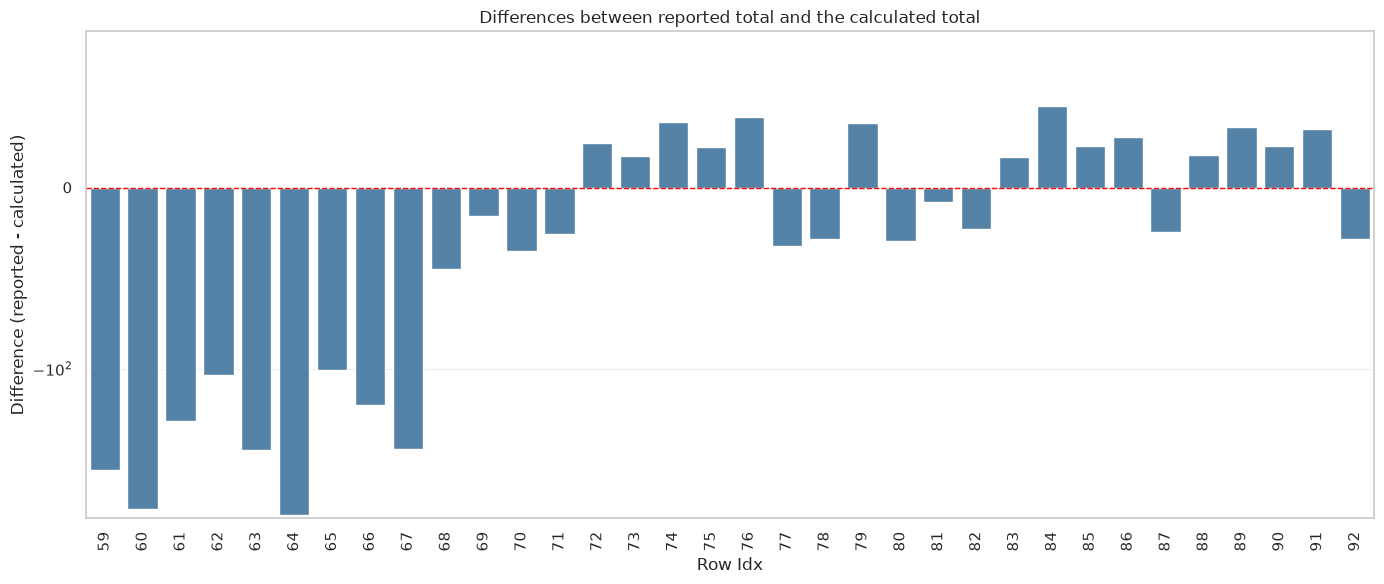

The chart shows the differences between the reported total in
the CSV and the calculated total obtained by multiplying the
quantity by the unit price for each product. Negative values
indicate that the reported total is lower than the calculated
total, while positive values indicate that it is higher; a
symmetric logarithmic scale is used on the Y-axis to make
differences of varying magnitudes easier to visualize.
+ ---------------------------------------------------------
+ Time to load: 0.5718 seconds
+ =========================================================


In [59]:
# DATA ANALYSIS, 2. CHECK OF COLUMN VALUE TOTAL
# =============================================
tInit: float = time.time()

# CheckTotalColumnValues
# ----------------------
# Convert columns to numeric and check for negative or zero values
# 
# @param pd.DataFrame pDf The pandas dataframe to check
# @return None
def CheckTotalColumnValues(pDf: pd.DataFrame) -> Dict[str, any]:
  # Ensure numeric conversion
  pDf['cantidad'] = pd.to_numeric(pDf['cantidad'], errors='coerce')
  pDf['precio_unitario'] = pd.to_numeric(pDf['precio_unitario'], errors='coerce')
  pDf['total'] = pd.to_numeric(pDf['total'], errors='coerce')

  # Get the expected Total
  pDf['total_temp'] = pDf['cantidad'] * pDf['precio_unitario']

  # Filter rows where both total amount do not match (using np.isclose with tolerance of 0.01)
  # Only check rows where any columns are null
  maskNoNull = pDf['cantidad'].notna() & pDf['precio_unitario'].notna() & pDf['total'].notna()
  inconsistencies = pDf[maskNoNull & (~np.isclose(pDf['total_temp'], pDf['total'], atol=0.01))]

  print(f"Rows with different totals: {len(inconsistencies)}")
  csl.SectionBreak(0,0)
  print("Snapshot of rows with inconsistent total calculation:")
  print(inconsistencies[['producto', 'cantidad', 'precio_unitario', 'total', 'total_temp']].head(10))

  res:Dict[str, any] = cht.PlotSalesAnalytics([
      'total', 
      'total_temp'
    ], {
      'figsize': (14, 6),
      'color': 'steelblue',
      'yscale': 'symlog',
      'linthresh': 100,
      'title': 'Differences between reported total and the calculated total',
      'xlabel': 'Row Idx',
      'ylabel': 'Difference (reported - calculated)'
    }, 
    'diff',
    inconsistencies,
  )

  print(f"The chart shows the differences between the reported total in" +
        "\nthe CSV and the calculated total obtained by multiplying the" +
        "\nquantity by the unit price for each product. Negative values" +
        "\nindicate that the reported total is lower than the calculated" +
        "\ntotal, while positive values indicate that it is higher; a" +
        "\nsymmetric logarithmic scale is used on the Y-axis to make" +
        "\ndifferences of varying magnitudes easier to visualize.")
  
  return res
  
csl.SectionBegin("CHECK OF TOTAL COLUMN VALUE", 0)
print("+ Summary of rows with incorrect Total amount:")
csl.SectionBreak(0,0)

res = CheckTotalColumnValues(df)
if not res['bOk']: 
  print(f"Error({res['err']['code']}): In {res['err']['whre']}:")
  print(res['err']['mssg'])

csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

In [60]:
# DATA ANALYSIS, 4. CHECK OF INVALID DATE VALUES
# ==============================================
tInit: float = time.time()

# CheckInvalidDates
# -----------------
# Try to convert the date column to proper datetime format
# errors='coerce' converts all invalid dates to NaN
# 
# @param string pColumn Name of the column to convert to proper date format
# @return None
def CheckInvalidDates(pDf: pd.DataFrame, pColumn:str = 'fecha') -> Dict[str, any]:
  properDateTime: pd.Series = pd.to_datetime(pDf[pColumn], errors='coerce')
  
  # How many dates were successfully converted and how many failed
  totRows: int = len(pDf)
  totProperDates: int = properDateTime.notna().sum()
  totInvalidDates: int = properDateTime.isna().sum()

  print(f"Total rows: {totRows}")
  print(f"Valid dates converted successfully: {totProperDates}")
  print(f"Invalid or null dates detected: {totInvalidDates}")

  # Show some of the rows with dates that failed
  print("\nSnapshot of rows with invalid dates:")
  print(pDf[properDateTime.isna()][pColumn].head(10))

  return {
    'category': pColumn,
    'total': totRows,
    'valid': totProperDates,
    'errors': totInvalidDates
  }

  
# Execute script
csl.SectionBegin("CHECK OF INVALID DATE VALUES", 0)
print("+ Summary of conversion date column state:")
csl.SectionBreak(0,0)

resInvalidDates: Dict[str, any] = CheckInvalidDates(df, "fecha")

csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ CHECK OF INVALID DATE VALUES
+ Summary of conversion date column state:
+ ---------------------------------------------------------
Total rows: 320
Valid dates converted successfully: 302
Invalid or null dates detected: 18

Snapshot of rows with invalid dates:
0             NaN
1             NaN
2             NaN
3             NaN
4             NaN
25     2026-02-30
26     2026-13-10
27     2026-10-45
28    no_es_fecha
29     31/02/2026
Name: fecha, dtype: str
+ ---------------------------------------------------------
+ Time to load: 0.0088 seconds
+ =========================================================


In [61]:
# DATA ANALYSIS, 5. CHECK OF INVALID NUMERIC VALUES
# ==========================================================
tInit: float = time.time()

# CheckInvalidNumericValues
# -------------------------
# Convert columns to numeric and check for invalid values
# 
# @param pd.DataFrame pDf The pandas dataframe to check
# @return list[dict] Validation results for each numeric column
def CheckInvalidNumericValues(pDf: pd.DataFrame) -> list[dict]:
  # Convert to numeric by forcing errors to NaN values for security
  pDf['cantidad_num'] = pd.to_numeric(pDf['cantidad'], errors='coerce')
  pDf['precio_unitario_num'] = pd.to_numeric(pDf['precio_unitario'], errors='coerce')
  pDf['total_num'] = pd.to_numeric(pDf['total'], errors='coerce')

  # Identify rows with invalid values (null, non-numeric, zero or negative)
  invalidPrices: pd.Series = pDf['precio_unitario_num'].isna() | (pDf['precio_unitario_num'] <= 0)
  invalidAmount: pd.Series = pDf['cantidad_num'].isna() | (pDf['cantidad_num'] <= 0)
  invalidTotales: pd.Series = pDf['total_num'].isna() | (pDf['total_num'] <= 0)

  # Identify rows with at least one invalid numeric value
  invalidRows: pd.DataFrame = pDf[invalidAmount | invalidPrices | invalidTotales]

  # Show summary of results
  print(f"Rows with any invalid numeric values: {len(invalidRows)}")
  print(f"Rows with invalid [precio_unitario]:  {int(invalidPrices.sum())}")
  print(f"Rows with invalid [cantidad]:         {int(invalidAmount.sum())}")
  print(f"Rows with invalid [total]:            {int(invalidTotales.sum())}")

  csl.SectionBreak(0,0)
  print("Snapshot of rows with invalid numeric values:")
  print(invalidRows[['fecha', 'producto', 'cantidad', 'precio_unitario', 'total']].head(10))

  # Prepare results for the quality summary chart
  totRows: int = len(pDf)
  res: list[dict] = []

  for col, mask in [
    ('cantidad', invalidAmount),
    ('precio_unitario', invalidPrices),
    ('total', invalidTotales)
  ]:
    totErrors: int = int(mask.sum())
    res.append({
      'category': col,
      'total': totRows,
      'valid': totRows - totErrors,
      'errors': totErrors
    })
    
  return res
  
csl.SectionBegin("CHECK OF NEGATIVE OR ZERO NUMERIC VALUES", 0)
print("+ Summary of rows with weird numeric values:")
csl.SectionBreak(0,0)

resNumericValues: list[dict] = CheckInvalidNumericValues(df)

csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)

+ =========================================================
+ CHECK OF NEGATIVE OR ZERO NUMERIC VALUES
+ Summary of rows with weird numeric values:
+ ---------------------------------------------------------
Rows with any invalid numeric values: 45
Rows with invalid [precio_unitario]:  15
Rows with invalid [cantidad]:         16
Rows with invalid [total]:            35
+ ---------------------------------------------------------
Snapshot of rows with invalid numeric values:
         fecha               producto  cantidad  precio_unitario   total
10  2026-10-07       Teclado mecanico       NaN           103.59  310.77
11  2026-09-22  Auriculares Bluetooth       NaN            95.82   95.82
12  2026-10-11              Webcam HD       NaN            24.36   24.36
13  2026-10-12          Disco SSD 1TB       NaN           140.97  281.94
14  2026-10-02          Disco SSD 1TB       NaN           135.78  271.56
15  2026-10-04        Cargador rapido       1.0              NaN   36.46
16  2026-10

+ =========================================================
+ CHART: CHECK OF INVALID VALUES (DATES, NUMERIC)
+ ---------------------------------------------------------


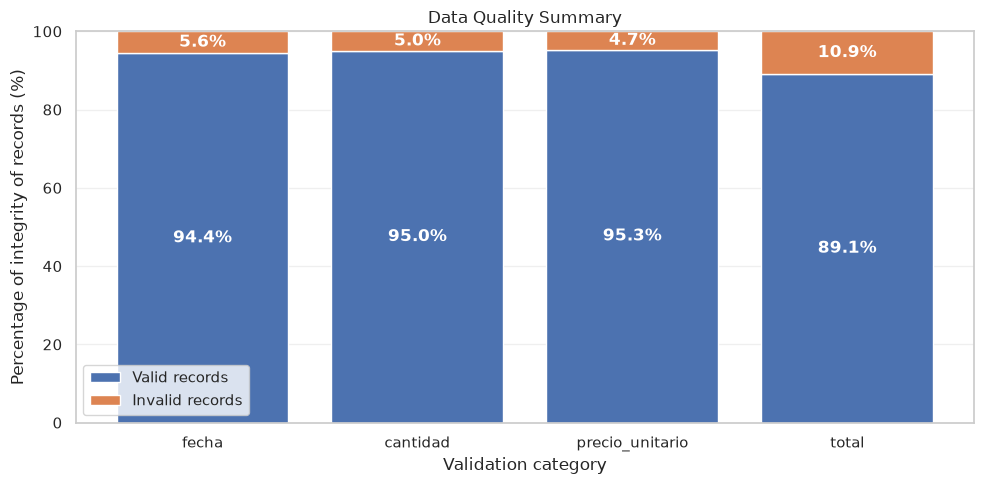

+ ---------------------------------------------------------
+ Time to load: 0.3072 seconds
+ =========================================================


In [62]:
# DATA ANALYSIS, 6. CHECK OF INVALID VALUES (DATES, NUMERIC)
# ==========================================================
tInit: float = time.time()

csl.SectionBegin("CHART: CHECK OF INVALID VALUES (DATES, NUMERIC)", 0)
csl.SectionBreak(0,0)

res = cht.PlotSalesAnalytics((
  [resInvalidDates] + resNumericValues
  ), {
    'figsize': (10, 5),
    'title': 'Data Quality Summary',
    'xlabel': 'Validation category',
    'ylabel': 'Percentage of integrity of records (%)',
    'fontsize': 12,
    'fontweight': 'bold',
  }, 
  'qty'
)

if not res['bOk']: 
  print(f"Error({res['err']['code']}): In {res['err']['whre']}:")
  print(res['err']['mssg'])

csl.SectionBreak(0,0)
tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)


+ =========================================================
+ CHECK OF OUTLIERS VALUES
+ Summary of rows with possible outlier values on Price and Quantity:
+ ---------------------------------------------------------
Quantity highest values: 5
 
          fecha          producto  cantidad  precio_unitario     total
97   2026-10-15  Altavoz portatil     845.0           117.16  99000.20
94   2026-10-07  Teclado mecanico     794.0            44.07  34991.58
100  2026-09-25     Disco SSD 1TB     394.0           107.57  42382.58
96   2026-09-26      Funda tablet     315.0            18.08   5695.20
95   2026-09-29         Webcam HD     304.0            69.97  21270.88
+ ---------------------------------------------------------
Price highest values: 5
 
          fecha             producto  cantidad  precio_unitario     total
104  2026-09-29     Teclado mecanico       1.0          11922.0   11922.0
102  2026-10-08    Raton inalambrico       2.0          11838.0   23676.0
103  2026-09-19     

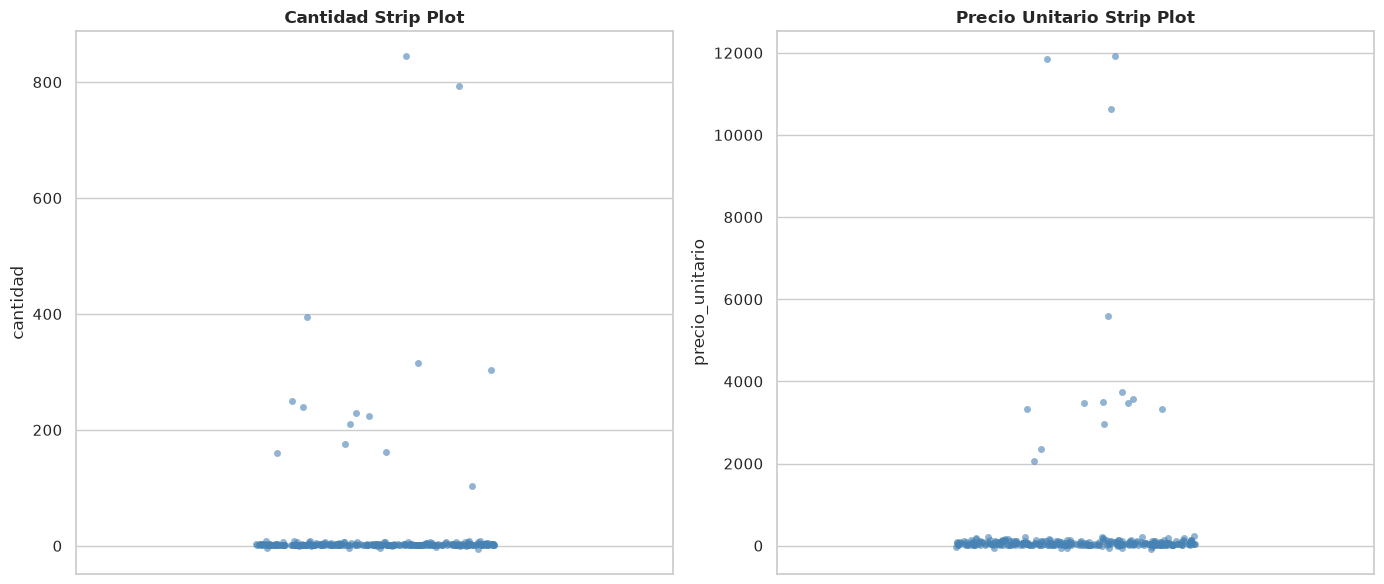

+ ---------------------------------------------------------
+ Time to load: 0.3036 seconds
+ =========================================================


In [63]:
# DATA ANALYSIS
# =============
# 6. CHECK OF OUTLIERS VALUES
# ---------------------------
tInit: float = time.time()

# CheckOutliersValues
# -------------------
# Convert columns ensuring numeric values and show the biggest 
# values to detect prices or quantities that makes no sense
# 
# @param pd.DataFrame pDf The pandas dataframe to check
# @return None
def CheckOutliersValues(pDf: pd.DataFrame) -> None:
  # Ensure numeric conversion
  pDf['qty_temp'] = pd.to_numeric(pDf['cantidad'], errors='coerce')
  pDf['prc_temp'] = pd.to_numeric(pDf['precio_unitario'], errors='coerce')
  
  # Show the highest values
  highestQty = pDf.nlargest(5, 'qty_temp')
  print(f"Quantity highest values: {len(highestQty)}")
  csl.nbsp()
  print(highestQty[['fecha', 'producto', 'cantidad', 'precio_unitario', 'total']].head(5))
  csl.SectionBreak(0,0)

  highestPrc = pDf.nlargest(5, 'prc_temp')
  print(f"Price highest values: {len(highestPrc)}")
  csl.nbsp()
  print(highestPrc[['fecha', 'producto', 'cantidad', 'precio_unitario', 'total']].head(5))
  
  # Show type chart Line Plot to check Outliers on Quantity and Price
  # Shared base configuration Chart
  baseCfgCharts: dict = {
    "ncols": 2,
    "figsize": (14, 6),
    "color": "steelblue",
    "fontweight": "bold",
    "fontsize": 12
  }
  
  # Histogram Plot Chart
  # cfgCurrPlotChart: Dict[str, any] = baseCfgCharts | { 'alpha': .6, 'bins': 30, 'kde': True }
  
  # Line Plot Chart
  # cfgCurrPlotChart: Dict[str, any] = { 'alpha': .8, 'linewidth': 1.5 }
  
  # Scatter Plot Chart
  # cfgCurrPlotChart: Dict[str, any] = baseCfgCharts | {'mode': 'seq', 'alpha': .6, 'size': 30 }
  # cht.PlotSalesAnalytics(pDf, ['cantidad', 'precio_unitario'], cfgCurrPlotChart, 'scatter')
  
  # Strip Plot Chart
  cfgCurrPlotChart: Dict[str, any] = baseCfgCharts | { 'alpha': .6, 'jitter': .2, 'size': 5 }
  cht.PlotSalesAnalytics(['cantidad', 'precio_unitario'], cfgCurrPlotChart, 'strip', pDf)
  
csl.SectionBegin("CHECK OF OUTLIERS VALUES", 0)
print("+ Summary of rows with possible outlier values on Price and Quantity:")
csl.SectionBreak(0,0)
CheckOutliersValues(df)
csl.SectionBreak(0,0)

tEnd: float = time.time()
print(f"+ Time to load: {tEnd - tInit:.4f} seconds")
csl.SectionEnd(0)